# 3. Backtesting Design (WHEN)

## Summary

**What this notebook covers:** the temporal backtesting framework used to evaluate the WHEN target (`next_1y` / `next_2y`) on `snapshots_df`: (1) distribution of snapshots by year, (2) final holdout split, (3) walk-forward fold generation with censoring and artist-level partitioning, (4) per-fold metrics reporting. All logic lives in `src/backtesting.py`; this notebook only imports and calls it.

**Key findings so far**
- **Distribution:** 5,438,765 snapshots over 1892 to 2026. Volume peaks at 191,013 in 2020 and falls to 117,600 in 2025. The 14 low-volume years (1892 to 1907) hold about 0.05% of snapshots.
- **Final holdout:** `year` 2018 to 2023 (1,020,151 snapshots, 18.8%). 2024 to 2025 (`excluded_recent`, submission lag) and 2026 (`demo`, partial year) are kept apart for demo use only.
- **Baseline floor per fold:** the historical WHEN baseline reaches PR-AUC 0.605 to 0.713 (`next_1y`) and 0.698 to 0.787 (`next_2y`) over folds 1 to 5, improving in recent tranches, not degrading.
- **Final holdout (2018 to 2023, evaluated once):** the locked XGBoost reaches PR-AUC 0.7851 and ROC-AUC 0.7653 for `next_1y` (baseline 0.7350 and 0.7185) and 0.8352 and 0.7494 for `next_2y` (baseline 0.7894 and 0.6993). At the 0.5 threshold, 71.2% of the `next_1y` snapshots flagged as followed by new work were, and the model caught 73.5% of those that were.
- **2026 is a partial year** (dump dated 2026-09-01): 54,958 snapshots, kept in the data but flagged, not part of the low-volume criterion.

Design decisions are logged in `docs/decisions.md`.

## 0. Data Loading

In [1]:
import sys  # needed to extend the module search path
sys.path.append('../src')  # make src/ importable inside notebooks/
from backtesting import load_or_build_snapshots  # reusable loader lives in src/backtesting.py

snapshots_df = load_or_build_snapshots()  # read cached snapshots, build and cache them if the file is missing
snapshots_df.shape  # confirm row and column counts after loading

(5438765, 23)

## 1. Distribution Inspection

### Question: how are snapshots spread across calendar years, and which years are too thin to anchor a cutoff or a fold?

In [2]:
from backtesting import year_distribution  # reusable function lives in src/backtesting.py

year_table = year_distribution(snapshots_df)  # snapshots per year with share, cumulative share, partial and low-volume flags
print(f"low-volume threshold (p10 of complete years): {year_table.attrs['low_volume_threshold']:,.0f} snapshots")  # cut used for the flag
year_table[year_table['low_volume'] | year_table['partial']]  # flagged years only (low volume plus the partial year)

low-volume threshold (p10 of complete years): 590 snapshots


,snapshots,share,cum_share,partial,low_volume
year,,,,,
1892,1,1.838653e-07,1.838653e-07,False,True
1894,3,5.515958e-07,7.354611e-07,False,True
1895,3,5.515958e-07,1.287057e-06,False,True
1896,12,2.206383e-06,3.493440e-06,False,True
1897,22,4.045036e-06,7.538476e-06,False,True
1898,60,1.103192e-05,1.857039e-05,False,True
1899,51,9.377129e-06,2.794752e-05,False,True
1900,42,7.722341e-06,3.566986e-05,False,True
1901,105,1.930585e-05,5.497572e-05,False,True


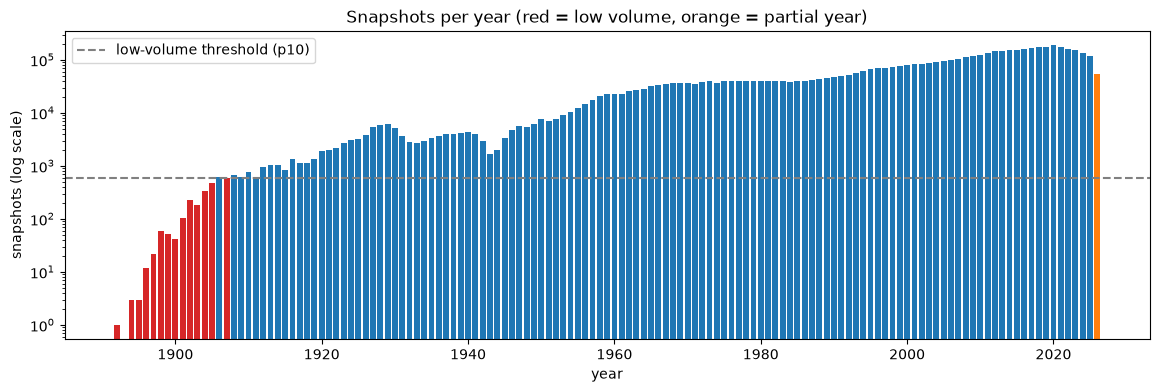

In [3]:
from backtesting import plot_year_distribution  # reusable plotting lives in src/backtesting.py

plot_year_distribution(year_table)  # bar chart per year on a log axis, flagged years colored

In [4]:
year_table.tail(25)  # recent years, where the holdout and fold boundaries will sit

,snapshots,share,cum_share,partial,low_volume
year,,,,,
2002,82597,0.015187,0.409170,False,False
2003,86707,0.015942,0.425112,False,False
2004,90855,0.016705,0.441817,False,False
2005,93965,0.017277,0.459094,False,False
2006,100044,0.018395,0.477489,False,False
2007,105215,0.019345,0.496834,False,False
2008,111270,0.020459,0.517293,False,False
2009,116315,0.021386,0.538679,False,False
2010,123398,0.022689,0.561368,False,False


### Interpretation

The data holds 5,438,765 snapshots. The low-volume threshold is the 10th percentile of yearly counts over complete years (2026 excluded), 590 snapshots. It flags 14 years, all between 1892 and 1907, which together hold about 0.05% of snapshots, so none of them sits near a plausible holdout or fold boundary. 2026 has 54,958 snapshots (1.01%) and is flagged separately as `partial` because the dump is dated 2026-09-01.

Volume peaks at 191,013 in 2020 and declines every year to 117,600 in 2025. This is very likely Discogs submission lag (recent years are still being backfilled by users), not a real drop in activity. It must not be read as a signal about recent years.

### Decision

No cutoff fixed here (distribution inspection only). 2026 stays in the data and in the table, flagged as partial, but is not treated as a real test period (to be settled in the holdout design). The 2020 to 2025 decline is treated as submission lag, which raises an open question for the holdout: whether the most recent 1 to 2 years, with artificially low counts, should be part of the final holdout.

## 2. Final Holdout Split

### Question: which snapshots form the final holdout, and which recent years must stay out of both training and the evaluation metric?

In [5]:
from backtesting import split_holdout, split_summary  # reusable functions live in src/backtesting.py

parts = split_holdout(snapshots_df)  # development, holdout, excluded_recent and demo buckets
split_summary(parts)  # rows, share, year range and artists per bucket

,snapshots,share,first_year,last_year,artists
development,4111163.0,0.755900,1892.0,2017.0,844705.0
holdout,1020151.0,0.187570,2018.0,2023.0,291481.0
excluded_recent,252493.0,0.046425,2024.0,2025.0,111942.0
demo,54958.0,0.010105,2026.0,2026.0,34199.0


### Interpretation

The split puts 4,111,163 snapshots (75.6%, 1892 to 2017) in development, 1,020,151 (18.8% of all snapshots, 18.95% of the 5,383,807 that exclude 2026, 2018 to 2023) in the final holdout, 252,493 (4.6%, 2024 to 2025) in `excluded_recent`, and 54,958 (1.0%, 2026) in `demo`. Every snapshot lands in exactly one bucket. The holdout is the most recent block of complete years not affected by Discogs submission lag, and it lands within about 1 point of the 20% target.

`excluded_recent` is kept apart from `demo` on purpose. 2024 and 2025 are complete years, but their counts (134,893 and 117,600) are artificially low because users are still backfilling them, so they would distort both training and the evaluation metric. 2026 is excluded for a different reason: the dump ends on 2026-09-01, so the year is only partly observed. Neither bucket is lost, both stay available for the demo.

### Decision

Final holdout = snapshots with `year` 2018 to 2023, untouched until the final model evaluation and never used in walk-forward folds or tuning. Development = `year` <= 2017, the only pool the walk-forward folds may draw from. 2024 to 2025 (`excluded_recent`) and 2026 (`demo`) are excluded from training and evaluation and kept for demo use only, each flagged separately. Logged in `docs/decisions.md`.

### Question: which development rows have a `next_1y` / `next_2y` label that reaches into the holdout years, and must stay out of the final model's training data?

In [6]:
from backtesting import holdout_gap  # reusable function lives in src/backtesting.py

final_train, boundary_gap = holdout_gap(parts['development'])  # development rows safe for training vs rows whose label window reaches into the holdout
print(f"final_train: {len(final_train):,} rows (years {final_train['year'].min()}-{final_train['year'].max()})")  # usable to train the final model
print(f"boundary_gap: {len(boundary_gap):,} rows (years {boundary_gap['year'].min()}-{boundary_gap['year'].max()}, {len(boundary_gap) / len(parts['development']):.1%} of development)")  # excluded from training use

final_train: 3,786,030 rows (years 1892-2015)
boundary_gap: 325,133 rows (years 2016-2017, 7.9% of development)


### Interpretation

`next_1y` and `next_2y` are not instantaneous: they look 1 to 2 years past the snapshot's own year. A development row from 2016 or 2017 therefore has a label that already encodes activity in 2018 or 2019, inside the sealed holdout. Using the longer horizon (2 years) as the gap covers both targets with one rule.

### Decision

Development rows with `year >= 2016` (holdout start minus 2) are not used to train the model that is evaluated on the holdout: 325,133 rows (7.9% of development) leave `final_train`, which keeps 3,786,030 rows (1892 to 2015). These rows stay in `development` so the walk-forward test tranches can still use them as test rows. Logged in `docs/decisions.md`.

## 2b. Feature Point-in-Time Audit

### Question: does every snapshot column use only information up to and including its own `year`, so that the same artist appearing in train and test of one fold is not leakage?

In [7]:
import pandas as pd  # dataframe library used to load the Works table and join the results
from backtesting import point_in_time_check  # reusable function lives in src/backtesting.py

works_df = pd.read_parquet('../data/processed/works_checkpoint.parquet')  # cleaned Works table, input of build_snapshots
audit = pd.DataFrame({y: point_in_time_check(works_df, y) for y in (1990, 2000, 2010)})  # rows that change when Works after the cutoff are removed
audit.columns = [f'cutoff_{y}' for y in audit.columns]  # label each column by its cutoff year
audit  # 0 = identical with and without the future

,cutoff_1990,cutoff_2000,cutoff_2010
artist_id,0,0,0
year,0,0,0
cutoff_year,0,0,0
work_source,0,0,0
genres,0,0,0
works_so_far_this_year,0,0,0
albums_so_far_this_year,0,0,0
singles_so_far_this_year,0,0,0
is_album_like,0,0,0
is_single_like,0,0,0


### Interpretation

The truncation test removes every dated Work after a cutoff year for a random sample of 30,000 artists, rebuilds the snapshots, and compares every column on the snapshots up to the cutoff. Every feature and identifier column is identical (0 rows differ) at the 1990, 2000 and 2010 cutoffs. Only the targets differ, as designed: `next_1y`, `next_2y` and `new_style` look forward by definition.

The test has two blind spots, so a clean result is not enough on its own. It cuts at year level, so it cannot see the within-year leak of `works_this_year`, `albums_this_year` and `singles_this_year` (they count same-year Works that come later in the sort order). And undated Works have no year to cut on, so `artist_undated_work_count` and `year_missing` are identical by construction, not by proof. In addition, `work_source` depends on a whole-catalog rule: a Work is synthetic only when the artist has 3 or more standalone releases in the full dump, which includes releases that come later.

### Decision

Safe as model inputs: `works_so_far_this_year`, `albums_so_far_this_year`, `singles_so_far_this_year`, `is_album_like`, `is_single_like`, `history_count`, `years_since_last`, `years_active_so_far`, `historical_rate`, `genres`. `year` is not a leak but a drift hazard. Not usable until resolved: `works_this_year`, `albums_this_year`, `singles_this_year` (within-year leak), `artist_undated_work_count`, `year_missing` (whole-catalog aggregate, timing unknowable), `work_source` (whole-catalog selection). `artist_id` and `work_id` are keys only. Full column-by-column table logged in `docs/decisions.md`.

## 2c. Cleaning Pipeline Cross-Time Audit

### Question: does any cleaning rule in `src/works.py` decide a Work's presence using Works of the same artist dated later, so that a Work in year Y is influenced by a Work in year Y+n?

In [8]:
from backtesting import presence_truncation_check  # reusable function lives in src/backtesting.py
from works import remove_fuzzy_duplicate_titles  # production fuzzy-dedup filter lives in src/works.py

fuzzy_input = pd.read_parquet('../data/processed/works_checkpoint_dedup.parquet')  # Works table as it enters the fuzzy-dedup step
fuzzy_audit = pd.DataFrame({y: presence_truncation_check(remove_fuzzy_duplicate_titles, fuzzy_input, y) for y in (1990, 2000, 2010)})  # survival with vs without Works after the cutoff
fuzzy_audit  # dated_changed = dated Works whose survival depends on later Works

,1990,2000,2010
dated_works,241944,318708,429603
dated_changed,19,17,21
undated_works,75717,75717,75717
undated_changed,170,89,26


In [9]:
from works import remove_catalog_number_duplicates  # production catalog-number dedup filter lives in src/works.py

catno_input = pd.read_parquet('../data/processed/works_checkpoint_fuzzy_dedup.parquet')  # Works table as it enters the catalog-number step (and the mass-upload step)
releases_labels = pd.read_parquet('../data/processed/releases.parquet', columns=['release_id', 'master_id', 'is_main_release', 'released', 'labels'])  # label and catalog numbers per release
groups = catno_input.groupby(['artist_id', 'title_normalized'])  # same-artist, same-title groups the filter targets
in_scope = (groups['year'].nunique() >= 2) & ~groups['is_reissue_tagged'].any()  # multi-year groups with no reissue tag
scope_artists = in_scope[in_scope].index.get_level_values(0).unique()  # every artist with at least one in-scope group
catno_scope = catno_input[catno_input['artist_id'].isin(scope_artists)]  # all Works of those artists
catno_audit = pd.DataFrame({y: presence_truncation_check(lambda w: remove_catalog_number_duplicates(w, releases_labels), catno_scope, y, n_artists=len(scope_artists), n_big_artists=0) for y in (1990, 2000, 2010)})  # whole in-scope population, no sampling
catno_audit  # dated_changed = dated Works whose survival depends on later Works

,1990,2000,2010
dated_works,492803,631386,792875
dated_changed,0,0,0
undated_works,113390,113390,113390
undated_changed,12,8,6


In [10]:
from backtesting import mass_upload_truncation_check  # reusable function lives in src/backtesting.py
from works import remove_mass_upload_artists  # production mass-upload exclusion lives in src/works.py

mass_upload_truncation_check(catno_input, remove_mass_upload_artists, cutoff_years=(1990, 2000, 2010, 2018, 2019, 2023))  # flagged artists with vs without Works after each cutoff

,flagged_full,flagged_truncated,only_truncated,only_full
cutoff,,,,
1990,1,0,0,1
2000,1,0,0,1
2010,1,0,0,1
2018,1,1,0,0
2019,1,1,0,0
2023,1,1,0,0


In [11]:
catno_input[catno_input['artist_id'] == 6391827]['year'].value_counts().sort_index()  # the one flagged artist: years of its Works

year
2018.0    936
2019.0    794
2020.0      2
2021.0      1
2023.0     98
2024.0     23
Name: count, dtype: int64

In [12]:
from backtesting import master_year_provenance  # reusable function lives in src/backtesting.py

masters_years = pd.read_parquet('../data/processed/masters.parquet', columns=['master_id', 'year'])  # the year Discogs holds for each master
master_year_provenance(works_df, masters_years)  # origin of every master-side year in the final Works table

master_works                        1951057
same_as_masters_year                1852315
recovered_from_own_releases           37354
differs_from_present_master_year          0
still_missing                         61388
dtype: int64

### Interpretation

The test removes the Works dated after a cutoff (1990, 2000, 2010), reruns the production rule on the same artists, and checks whether any dated Work with `year <= cutoff` survives in one run and not in the other. Undated Works have no year to cut on; they are reported separately.

**What the results mean.** `src/works.py` builds the canonical catalog: the record of which Works are real, distinct Works and which are duplicates of one another. That step legitimately uses the artist's full history, the same way Discogs keeps re-resolving duplicates with complete, non-time-restricted information, and the model will be deployed against that fully curated data. Restricting dedup to past-only data would make the catalog less accurate, not more sound. So a Work whose survival changes when the future is removed is expected behavior for a full-history dedup step, not leakage. The point-in-time requirement applies only to the feature and label computation in `snapshots.py` (what the model would know at prediction time), which section 2b verified column by column. These are two different categories of issue: "catalog built with full history" is not "model trained on leaked future labels" (that one is handled by the gap in sections 2 and 3).

- **Fuzzy dedup (`remove_fuzzy_duplicate_titles`):** 19, 17 and 21 dated Works change survival at the three cutoffs (0.008%, 0.005%, 0.005% of 241,944, 318,708 and 429,603), caused by the 10-title alphabetical window. The earliest year always wins a pair and no attributes are merged. Recorded as a measurement of how much a full-history dedup differs from a truncated one, no fix.
- **Catalog-number dedup (`remove_catalog_number_duplicates`):** 0 dated Works change at any cutoff over the whole in-scope population (492,803 to 792,875 dated Works).
- **Mass-upload exclusion (`remove_mass_upload_artists`):** flags exactly one artist (6391827, 1,854 Works, all 2018 to 2024), a whole-catalog decision by design.
- **Missing-year recovery (`recover_missing_master_years`):** the adopted step, not one of the abandoned imputations. Of 1,951,057 master Works, 1,852,315 keep the year in `masters.parquet`, 37,354 were filled from the master's own Releases, 0 differ from a year Discogs already holds, 61,388 stay missing. No trace of the three abandoned methods.
- **Undated Works** change survival too (an undated Work loses to any dated twin, and the twin disappears when the future is cut). Expected, they are not snapshot rows.

### Decision

No change to `src/works.py` and no rebuild. The truncation numbers stay as a record of what was tested, interpreted as expected behavior of a full-history catalog. Logged in `docs/decisions.md`.

## 3. Walk-Forward Fold Generation

### Question: what do the five expanding-window folds look like once train rows whose label window reaches into the test tranche are excluded (gap), and do the test sets keep their natural population of artists with history?

In [13]:
from backtesting import make_folds, fold_summary  # reusable functions live in src/backtesting.py

low_volume_years = year_table[year_table['low_volume']].index  # years that no test tranche may touch
folds = make_folds(parts['development'], n_folds=5, test_years=5, target='next_1y', low_volume_years=low_volume_years)  # 5 calendar-year tranches of 5 years, expanding train, 2-year gap before each tranche
fold_summary(folds)[['train_years', 'gap_years', 'test_years']]  # windows of every fold

,train_years,gap_years,test_years
fold,,,
1,1892-1990,1991-1992,1993-1997
2,1892-1995,1996-1997,1998-2002
3,1892-2000,2001-2002,2003-2007
4,1892-2005,2006-2007,2008-2012
5,1892-2010,2011-2012,2013-2017


In [14]:
fold_summary(folds)[['gap_rows', 'train_rows', 'test_rows_raw', 'censored_rows', 'test_rows']]  # rows removed by the gap and censoring, final train and test sizes

,gap_rows,train_rows,test_rows_raw,censored_rows,test_rows
fold,,,,,
1,101120,1401791,329253,0,329253
2,143236,1688928,393213,0,393213
3,164334,2061043,476786,0,476786
4,205259,2496904,629330,0,629330
5,278347,3053146,779670,0,779670


In [15]:
fold_summary(folds)[['test_artists', 'test_rows_with_train_artist', 'share_with_train_artist', 'history_median']]  # who is in the test set: median prior works and share of rows by artists also seen in train

,test_artists,test_rows_with_train_artist,share_with_train_artist,history_median
fold,,,,
1,138352,111436,0.338451,2.0
2,163996,148005,0.376399,3.0
3,193421,196436,0.412000,3.0
4,235948,239184,0.380061,3.0
5,274757,323371,0.414754,4.0


### Interpretation

Each fold drops the 2 years before its test tranche from train: 101,120, 143,236, 164,334, 205,259 and 278,347 rows in folds 1 to 5. Final train sizes are 1,401,791, 1,688,928, 2,061,043, 2,496,904 and 3,053,146 rows, and test sizes 329,253, 393,213, 476,786, 629,330 and 779,670 (tranches 1993 to 1997, 1998 to 2002, 2003 to 2007, 2008 to 2012, 2013 to 2017, uneven because they follow the calendar). Censoring removes 0 rows because every development target is resolved.

With the artist-overlap rule gone, the test sets keep their natural population: the median `history_count` is 2, 3, 3, 3 and 4 (it was 0, 0, 1, 1, 1 under the old rule), and 33.8% to 41.5% of test rows belong to artists that also have rows in train. Having an artist on both sides of a fold is not leakage, because the features are point-in-time safe (section 2b) and the train labels are gapped.

Fold 5's test rows from 2016 and 2017 have labels that read activity up to 2019. That is not a leak: a label that needs real later activity is how `next_1y` / `next_2y` are defined for any row. The holdout's integrity only requires that holdout rows (2018 to 2023 snapshots) are never used in training or walk-forward evaluation, which holds.

### Decision

Folds are generated with the 2-year gap and without the overlap rule. Tranche length (5 calendar years) is still a provisional choice. Logged in `docs/decisions.md`.

## 4. Per-Fold Metrics Reporting

### Question: how does the historical WHEN baseline perform fold by fold, and does it degrade in more recent tranches?

In [16]:
from baselines import fit_when_baseline, score_when_baseline  # historical WHEN baseline lives in src/baselines.py
from backtesting import evaluate_folds  # reusable function lives in src/backtesting.py

folds_1y = make_folds(parts['development'], target='next_1y', low_volume_years=low_volume_years)  # folds censored on next_1y
report_1y = evaluate_folds(folds_1y, 'next_1y', fit_when_baseline, score_when_baseline)  # one row per fold, no averaging
report_1y  # PR-AUC with 95% artist-clustered CI, positive rate, ROC-AUC, sizes

,test_years,train_rows,test_rows,positive_rate,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc
fold,,,,,,,,
1,1993-1997,1401791,329253,0.445827,0.604838,0.595041,0.613845,0.642310
2,1998-2002,1688928,393213,0.435700,0.610142,0.600008,0.620342,0.657825
3,2003-2007,2061043,476786,0.446544,0.648194,0.639115,0.657364,0.686015
4,2008-2012,2496904,629330,0.491601,0.686098,0.677370,0.693506,0.704675
5,2013-2017,3053146,779670,0.511987,0.712629,0.705528,0.718831,0.714332


In [17]:
folds_2y = make_folds(parts['development'], target='next_2y', low_volume_years=low_volume_years)  # folds censored on next_2y
report_2y = evaluate_folds(folds_2y, 'next_2y', fit_when_baseline, score_when_baseline)  # one row per fold, no averaging
report_2y  # PR-AUC with 95% artist-clustered CI, positive rate, ROC-AUC, sizes

,test_years,train_rows,test_rows,positive_rate,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc
fold,,,,,,,,
1,1993-1997,1401791,329253,0.584660,0.697723,0.691126,0.703772,0.616488
2,1998-2002,1688928,393213,0.582585,0.708124,0.701525,0.714553,0.635334
3,2003-2007,2061043,476786,0.595047,0.741345,0.735137,0.747309,0.665771
4,2008-2012,2496904,629330,0.625508,0.768275,0.761744,0.774264,0.685520
5,2013-2017,3053146,779670,0.638840,0.786992,0.781809,0.791747,0.696399


### Interpretation

`evaluate_folds` fits the baseline on each fold's gapped train rows only, scores that fold's test rows, and reports one row per fold (no averaging). The baseline ranks rows by `historical_rate`. The CI is a 95% artist-clustered bootstrap with 1,000 draws.

| Fold | Test | `next_1y` positive rate | PR-AUC [95% CI] | PR-AUC / positive rate | ROC-AUC |
|---|---|---|---|---|---|
| 1 | 1993-1997 | 0.446 | 0.605 [0.595, 0.614] | 1.36 | 0.642 |
| 2 | 1998-2002 | 0.436 | 0.610 [0.600, 0.620] | 1.40 | 0.658 |
| 3 | 2003-2007 | 0.447 | 0.648 [0.639, 0.657] | 1.45 | 0.686 |
| 4 | 2008-2012 | 0.492 | 0.686 [0.677, 0.694] | 1.40 | 0.705 |
| 5 | 2013-2017 | 0.512 | 0.713 [0.706, 0.719] | 1.39 | 0.714 |

`next_2y`: positive rate 0.585, 0.583, 0.595, 0.626, 0.639; PR-AUC 0.698, 0.708, 0.741, 0.768, 0.787 (CIs 0.010 to 0.013 wide); PR-AUC / positive rate 1.19, 1.21, 1.25, 1.23, 1.23; ROC-AUC 0.616, 0.635, 0.666, 0.686, 0.696.

The baseline does not degrade in more recent tranches, it improves: PR-AUC and ROC-AUC rise in both tables, and the CIs of folds 1, 3 and 5 do not overlap. Part of the PR-AUC gain is the rising positive rate (a no-skill score has PR-AUC equal to the positive rate). Relative to that floor the lift is flat from fold 2 on (1.40, 1.45, 1.40, 1.39 for `next_1y`), so the cleaner reading is the ROC-AUC rise (0.642 to 0.714), which does not depend on the positive rate. The rise comes from the test populations and training sizes changing together (more history per artist, 1.4M to 3.1M train rows), so it cannot be attributed to one cause from this table. `next_2y` has higher PR-AUC than `next_1y` only because its positive rate is higher; its ROC-AUC is lower (0.616 to 0.696 against 0.642 to 0.714), the two-year window is harder to rank.

### Decision

The per-fold report works and is model-agnostic (any `fit_fn` / `score_fn` pair). These numbers are the baseline floor each later model must beat, fold by fold, before the holdout is touched. The holdout stays sealed. The bootstrap is a fast re-implementation (`_artist_bootstrap_pr_auc`) because `baselines._bootstrap_pr_auc` does not finish at fold size. Logged in `docs/decisions.md`.

## Model Comparison Setup

Every model below uses the same pieces: the same folds (`folds_1y`, `folds_2y`), the same feature allowlist and fit/score interface (`src/models.py`), and the same per-fold report (`evaluate_folds`). Each is fitted on a fold's train rows only and scored on that fold's test rows, then compared with the historical baseline and the models before it. The holdout stays sealed throughout.

Reading the tables: `pr_auc` is the area under the precision-recall curve (a score that ranks rows at random gets the positive rate), `pr_auc_lo` / `pr_auc_hi` are its 95% interval from resampling artists, and `roc_auc` is the chance that a random positive row is ranked above a random negative one (0.5 = random, 1.0 = perfect).

In [18]:
reports_1y = {'baseline': report_1y}  # per-fold reports for next_1y, one entry per model, filled step by step
reports_2y = {'baseline': report_2y}  # same for next_2y

## Step 1: Logistic Regression (no tuning)

### Question: does an untuned Logistic Regression on the allowlisted features beat the historical baseline in every fold, for `next_1y` and `next_2y`?

In [19]:
from models import make_logistic_regression  # reusable pair lives in src/models.py

reports_1y['logreg'] = evaluate_folds(folds_1y, 'next_1y', *make_logistic_regression('next_1y'))  # median imputation, standardized features, per fold
reports_1y['logreg']  # next_1y: PR-AUC with 95% CI, positive rate, ROC-AUC, sizes

,test_years,train_rows,test_rows,positive_rate,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc
fold,,,,,,,,
1,1993-1997,1401791,329253,0.445827,0.658937,0.649627,0.667691,0.688483
2,1998-2002,1688928,393213,0.435700,0.659826,0.649533,0.669573,0.696359
3,2003-2007,2061043,476786,0.446544,0.682906,0.673625,0.691816,0.714147
4,2008-2012,2496904,629330,0.491601,0.723808,0.715125,0.732083,0.735961
5,2013-2017,3053146,779670,0.511987,0.754487,0.747129,0.761019,0.751927


In [20]:
reports_2y['logreg'] = evaluate_folds(folds_2y, 'next_2y', *make_logistic_regression('next_2y'))  # same for next_2y
reports_2y['logreg']  # next_2y, same columns

,test_years,train_rows,test_rows,positive_rate,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc
fold,,,,,,,,
1,1993-1997,1401791,329253,0.584660,0.763343,0.757503,0.769035,0.685184
2,1998-2002,1688928,393213,0.582585,0.764361,0.758248,0.770592,0.687270
3,2003-2007,2061043,476786,0.595047,0.774797,0.768655,0.780591,0.695561
4,2008-2012,2496904,629330,0.625508,0.796841,0.790040,0.803471,0.711857
5,2013-2017,3053146,779670,0.638840,0.820363,0.814706,0.825311,0.731879


### Interpretation

Logistic Regression ranks rows better than the baseline in every fold, for both targets. For `next_1y` the area under the precision-recall curve goes from 0.605 (baseline) to 0.659 in fold 1 and from 0.713 to 0.754 in fold 5, and the ROC-AUC from 0.642 to 0.688 and from 0.714 to 0.752. Scores are higher in recent folds partly because the share of positive rows rises (0.446 to 0.512), so ROC-AUC, which does not depend on that share, is the cleaner trend to read.

In [21]:
metrics = ['pr_auc', 'pr_auc_lo', 'pr_auc_hi', 'roc_auc']  # columns shown side by side
pd.concat({name: report[metrics] for name, report in reports_1y.items()}, axis=1).round(3)  # next_1y, every model so far, fold by fold

baseline                             logreg                            
       pr_auc pr_auc_lo pr_auc_hi roc_auc pr_auc pr_auc_lo pr_auc_hi roc_auc
fold                                                                        
1       0.605     0.595     0.614   0.642  0.659     0.650     0.668   0.688
2       0.610     0.600     0.620   0.658  0.660     0.650     0.670   0.696
3       0.648     0.639     0.657   0.686  0.683     0.674     0.692   0.714
4       0.686     0.677     0.694   0.705  0.724     0.715     0.732   0.736
5       0.713     0.706     0.719   0.714  0.754     0.747     0.761   0.752

In [22]:
pd.concat({name: report[metrics] for name, report in reports_2y.items()}, axis=1).round(3)  # next_2y, every model so far, fold by fold

baseline                             logreg                            
       pr_auc pr_auc_lo pr_auc_hi roc_auc pr_auc pr_auc_lo pr_auc_hi roc_auc
fold                                                                        
1       0.698     0.691     0.704   0.616  0.763     0.758     0.769   0.685
2       0.708     0.702     0.715   0.635  0.764     0.758     0.771   0.687
3       0.741     0.735     0.747   0.666  0.775     0.769     0.781   0.696
4       0.768     0.762     0.774   0.686  0.797     0.790     0.803   0.712
5       0.787     0.782     0.792   0.696  0.820     0.815     0.825   0.732

### Interpretation

The 95% intervals of the baseline and Logistic Regression never overlap, so the gain is not a chance result of one split. The PR-AUC gain is largest in folds 1 and 2 (+0.054 and +0.050 for `next_1y`, +0.066 and +0.056 for `next_2y`) and +0.029 to +0.042 from fold 3 on. The model is untuned, linear, and only standardizes the heavy-tailed counts (no log transform), so this is a floor for these features, not their ceiling.

### Decision

Logistic Regression is the first reference for the models that follow. Median imputation of `years_since_last` and `historical_rate`, fitted on each fold's train rows, no indicator columns. Logged in `docs/decisions.md`.

## Step 2: Naive Bayes (no tuning)

### Question: how does a cheap probabilistic reference, Gaussian Naive Bayes, compare with the baseline and Logistic Regression, even though its independence assumption clearly does not hold here?

In [23]:
from models import make_naive_bayes  # reusable pair lives in src/models.py

reports_1y['naive_bayes'] = evaluate_folds(folds_1y, 'next_1y', *make_naive_bayes('next_1y'))  # median imputation, GaussianNB defaults, per fold
reports_1y['naive_bayes']  # next_1y: PR-AUC with 95% CI, positive rate, ROC-AUC, sizes

,test_years,train_rows,test_rows,positive_rate,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc
fold,,,,,,,,
1,1993-1997,1401791,329253,0.445827,0.628484,0.619205,0.637298,0.651464
2,1998-2002,1688928,393213,0.435700,0.620643,0.610276,0.630742,0.649287
3,2003-2007,2061043,476786,0.446544,0.647071,0.637491,0.656622,0.679341
4,2008-2012,2496904,629330,0.491601,0.694959,0.687861,0.702014,0.706957
5,2013-2017,3053146,779670,0.511987,0.727111,0.720404,0.733258,0.726248


In [24]:
reports_2y['naive_bayes'] = evaluate_folds(folds_2y, 'next_2y', *make_naive_bayes('next_2y'))  # same for next_2y
reports_2y['naive_bayes']  # next_2y, same columns

,test_years,train_rows,test_rows,positive_rate,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc
fold,,,,,,,,
1,1993-1997,1401791,329253,0.584660,0.744324,0.738255,0.750034,0.658936
2,1998-2002,1688928,393213,0.582585,0.737369,0.730817,0.743963,0.648164
3,2003-2007,2061043,476786,0.595047,0.750843,0.744715,0.756961,0.665070
4,2008-2012,2496904,629330,0.625508,0.778210,0.772777,0.783699,0.685668
5,2013-2017,3053146,779670,0.638840,0.802491,0.797326,0.807210,0.710829


### Interpretation

Gaussian Naive Bayes sits close to the historical baseline and clearly below Logistic Regression. For `next_1y` its PR-AUC is 0.628, 0.621, 0.647, 0.695 and 0.727 against 0.605, 0.610, 0.648, 0.686 and 0.713 for the baseline, so it is a little better in folds 1, 2, 4 and 5 and level in fold 3 (the intervals overlap in folds 2, 3 and 4). Its ROC-AUC (0.651, 0.649, 0.679, 0.707, 0.726) is below the baseline in folds 2 and 3, level in fold 4 and above it in folds 1 and 5. Logistic Regression is better in every fold (PR-AUC 0.659 to 0.754, ROC-AUC 0.688 to 0.752).

In [25]:
metrics = ['pr_auc', 'pr_auc_lo', 'pr_auc_hi', 'roc_auc']  # columns shown side by side
pd.concat({name: report[metrics] for name, report in reports_1y.items()}, axis=1).round(3)  # next_1y, every model so far, fold by fold

baseline                             logreg                              \
       pr_auc pr_auc_lo pr_auc_hi roc_auc pr_auc pr_auc_lo pr_auc_hi roc_auc   
fold                                                                           
1       0.605     0.595     0.614   0.642  0.659     0.650     0.668   0.688   
2       0.610     0.600     0.620   0.658  0.660     0.650     0.670   0.696   
3       0.648     0.639     0.657   0.686  0.683     0.674     0.692   0.714   
4       0.686     0.677     0.694   0.705  0.724     0.715     0.732   0.736   
5       0.713     0.706     0.719   0.714  0.754     0.747     0.761   0.752   

     naive_bayes                              
          pr_auc pr_auc_lo pr_auc_hi roc_auc  
fold                                          
1          0.628     0.619     0.637   0.651  
2          0.621     0.610     0.631   0.649  
3          0.647     0.637     0.657   0.679  
4          0.695     0.688     0.702   0.707  
5          0.727     0.720     0.733   0.726

In [26]:
pd.concat({name: report[metrics] for name, report in reports_2y.items()}, axis=1).round(3)  # next_2y, every model so far, fold by fold

baseline                             logreg                              \
       pr_auc pr_auc_lo pr_auc_hi roc_auc pr_auc pr_auc_lo pr_auc_hi roc_auc   
fold                                                                           
1       0.698     0.691     0.704   0.616  0.763     0.758     0.769   0.685   
2       0.708     0.702     0.715   0.635  0.764     0.758     0.771   0.687   
3       0.741     0.735     0.747   0.666  0.775     0.769     0.781   0.696   
4       0.768     0.762     0.774   0.686  0.797     0.790     0.803   0.712   
5       0.787     0.782     0.792   0.696  0.820     0.815     0.825   0.732   

     naive_bayes                              
          pr_auc pr_auc_lo pr_auc_hi roc_auc  
fold                                          
1          0.744     0.738     0.750   0.659  
2          0.737     0.731     0.744   0.648  
3          0.751     0.745     0.757   0.665  
4          0.778     0.773     0.784   0.686  
5          0.802     0.797     0.807   0.711

### Interpretation

For `next_2y` Naive Bayes does better against the baseline than for `next_1y`: PR-AUC 0.744, 0.737, 0.751, 0.778 and 0.802 against 0.698, 0.708, 0.741, 0.768 and 0.787, a clear gain in folds 1 and 2 (+0.046, +0.029) and +0.010 to +0.015 after. Its ROC-AUC (0.659, 0.648, 0.665, 0.686, 0.711) is level with the baseline from fold 3 on. Logistic Regression is again better in every fold (PR-AUC 0.763 to 0.820).

### Decision

Naive Bayes is a reference point, not a candidate. About the mismatch: `GaussianNB` treats each feature as an independent Gaussian, but 13 of the 20 columns after encoding are 0/1 (two format flags and 11 genre columns) and the counts are skewed and correlated, so its probabilities are not trustworthy and it stays untuned. It is not replaced by a mixed Gaussian/Bernoulli model on purpose. Logged as a limitation in `docs/decisions.md`.

## Step 3: Random Forest (no tuning)

### Question: does an untuned Random Forest, which can use interactions and non-linear effects, beat Logistic Regression on the same features?

In [27]:
from models import make_random_forest  # reusable pair lives in src/models.py

reports_1y['random_forest'] = evaluate_folds(folds_1y, 'next_1y', *make_random_forest('next_1y'))  # median imputation, 200 trees of depth 12, per fold
reports_1y['random_forest']  # next_1y: PR-AUC with 95% CI, positive rate, ROC-AUC, sizes

,test_years,train_rows,test_rows,positive_rate,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc
fold,,,,,,,,
1,1993-1997,1401791,329253,0.445827,0.696227,0.687642,0.704204,0.730225
2,1998-2002,1688928,393213,0.435700,0.700842,0.691581,0.709577,0.739946
3,2003-2007,2061043,476786,0.446544,0.718595,0.710286,0.726425,0.746702
4,2008-2012,2496904,629330,0.491601,0.745657,0.738826,0.752099,0.752015
5,2013-2017,3053146,779670,0.511987,0.771087,0.765307,0.776592,0.763925


In [28]:
reports_2y['random_forest'] = evaluate_folds(folds_2y, 'next_2y', *make_random_forest('next_2y'))  # same for next_2y
reports_2y['random_forest']  # next_2y, same columns

,test_years,train_rows,test_rows,positive_rate,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc
fold,,,,,,,,
1,1993-1997,1401791,329253,0.584660,0.796039,0.790789,0.800989,0.731895
2,1998-2002,1688928,393213,0.582585,0.798442,0.793170,0.803405,0.732910
3,2003-2007,2061043,476786,0.595047,0.805160,0.799814,0.810156,0.730298
4,2008-2012,2496904,629330,0.625508,0.816406,0.810878,0.821262,0.730007
5,2013-2017,3053146,779670,0.638840,0.836015,0.832201,0.839661,0.745402


### Interpretation

The untuned Random Forest (200 trees, depth 12, at least 50 rows per leaf) is better than Logistic Regression in every fold for `next_1y`: PR-AUC 0.696, 0.701, 0.719, 0.746 and 0.771 against 0.659, 0.660, 0.683, 0.724 and 0.754, and ROC-AUC 0.730, 0.740, 0.747, 0.752 and 0.764 against 0.688, 0.696, 0.714, 0.736 and 0.752. The 95% intervals of the two models do not overlap in any fold. The gain over Logistic Regression is largest in the early folds (+0.037, +0.041, +0.036 PR-AUC) and smaller in the recent ones (+0.022, +0.017), where Logistic Regression has more training rows to work with and the gap narrows.

In [29]:
metrics = ['pr_auc', 'pr_auc_lo', 'pr_auc_hi', 'roc_auc']  # columns shown side by side
pd.concat({name: report[metrics] for name, report in reports_1y.items()}, axis=1).round(3)  # next_1y, every model so far, fold by fold

baseline                             logreg                              \
       pr_auc pr_auc_lo pr_auc_hi roc_auc pr_auc pr_auc_lo pr_auc_hi roc_auc   
fold                                                                           
1       0.605     0.595     0.614   0.642  0.659     0.650     0.668   0.688   
2       0.610     0.600     0.620   0.658  0.660     0.650     0.670   0.696   
3       0.648     0.639     0.657   0.686  0.683     0.674     0.692   0.714   
4       0.686     0.677     0.694   0.705  0.724     0.715     0.732   0.736   
5       0.713     0.706     0.719   0.714  0.754     0.747     0.761   0.752   

     naive_bayes                             random_forest            \
          pr_auc pr_auc_lo pr_auc_hi roc_auc        pr_auc pr_auc_lo   
fold                                                                   
1          0.628     0.619     0.637   0.651         0.696     0.688   
2          0.621     0.610     0.631   0.649         0.701     0.692   
3          0.647     0.637     0.657   0.679         0.719     0.710   
4          0.695     0.688     0.702   0.707         0.746     0.739   
5          0.727     0.720     0.733   0.726         0.771     0.765   

                        
     pr_auc_hi roc_auc  
fold                    
1        0.704   0.730  
2        0.710   0.740  
3        0.726   0.747  
4        0.752   0.752  
5        0.777   0.764

In [30]:
pd.concat({name: report[metrics] for name, report in reports_2y.items()}, axis=1).round(3)  # next_2y, every model so far, fold by fold

baseline                             logreg                              \
       pr_auc pr_auc_lo pr_auc_hi roc_auc pr_auc pr_auc_lo pr_auc_hi roc_auc   
fold                                                                           
1       0.698     0.691     0.704   0.616  0.763     0.758     0.769   0.685   
2       0.708     0.702     0.715   0.635  0.764     0.758     0.771   0.687   
3       0.741     0.735     0.747   0.666  0.775     0.769     0.781   0.696   
4       0.768     0.762     0.774   0.686  0.797     0.790     0.803   0.712   
5       0.787     0.782     0.792   0.696  0.820     0.815     0.825   0.732   

     naive_bayes                             random_forest            \
          pr_auc pr_auc_lo pr_auc_hi roc_auc        pr_auc pr_auc_lo   
fold                                                                   
1          0.744     0.738     0.750   0.659         0.796     0.791   
2          0.737     0.731     0.744   0.648         0.798     0.793   
3          0.751     0.745     0.757   0.665         0.805     0.800   
4          0.778     0.773     0.784   0.686         0.816     0.811   
5          0.802     0.797     0.807   0.711         0.836     0.832   

                        
     pr_auc_hi roc_auc  
fold                    
1        0.801   0.732  
2        0.803   0.733  
3        0.810   0.730  
4        0.821   0.730  
5        0.840   0.745

### Interpretation

For `next_2y` the pattern is the same: PR-AUC 0.796, 0.798, 0.805, 0.816 and 0.836 against 0.763, 0.764, 0.775, 0.797 and 0.820 for Logistic Regression (+0.033, +0.034, +0.030, +0.019, +0.016), with non-overlapping intervals. The ROC-AUC of the forest is flat across folds (0.732, 0.733, 0.730, 0.730, 0.745) while Logistic Regression's rises (0.685 to 0.732), which is why the gap closes in recent folds. Since the same 10 allowlisted features feed both models, the forest's edge points to non-linear effects and interactions in the history features that a linear model cannot use.

### Decision

Random Forest is the strongest model so far in every fold for both targets and the reference for HistGradientBoosting and XGBoost. Values are untuned common starting points, no search. Logged in `docs/decisions.md`.

## Step 4: HistGradientBoostingClassifier (no tuning)

### Question: does boosting, which also handles the missing values natively, improve on the Random Forest with the same features?

In [31]:
from models import make_hist_gradient_boosting  # reusable pair lives in src/models.py

reports_1y['hist_gb'] = evaluate_folds(folds_1y, 'next_1y', *make_hist_gradient_boosting('next_1y'))  # no imputation, 200 boosting rounds, per fold
reports_1y['hist_gb']  # next_1y: PR-AUC with 95% CI, positive rate, ROC-AUC, sizes

,test_years,train_rows,test_rows,positive_rate,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc
fold,,,,,,,,
1,1993-1997,1401791,329253,0.445827,0.697490,0.688855,0.705487,0.730441
2,1998-2002,1688928,393213,0.435700,0.702004,0.692843,0.710634,0.740872
3,2003-2007,2061043,476786,0.446544,0.719913,0.711543,0.727969,0.748511
4,2008-2012,2496904,629330,0.491601,0.745284,0.738208,0.752084,0.753405
5,2013-2017,3053146,779670,0.511987,0.770815,0.764887,0.776542,0.764401


In [32]:
reports_2y['hist_gb'] = evaluate_folds(folds_2y, 'next_2y', *make_hist_gradient_boosting('next_2y'))  # same for next_2y
reports_2y['hist_gb']  # next_2y, same columns

,test_years,train_rows,test_rows,positive_rate,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc
fold,,,,,,,,
1,1993-1997,1401791,329253,0.584660,0.796547,0.791383,0.801521,0.732461
2,1998-2002,1688928,393213,0.582585,0.798958,0.793686,0.803907,0.733911
3,2003-2007,2061043,476786,0.595047,0.805908,0.800454,0.811132,0.731969
4,2008-2012,2496904,629330,0.625508,0.816374,0.810928,0.821170,0.731165
5,2013-2017,3053146,779670,0.638840,0.836353,0.832450,0.840064,0.745987


### Interpretation

The untuned HistGradientBoostingClassifier lands on top of the Random Forest, not above it. For `next_1y` its PR-AUC is 0.697, 0.702, 0.720, 0.745 and 0.771 against 0.696, 0.701, 0.719, 0.746 and 0.771 for the forest, and its ROC-AUC 0.730, 0.741, 0.749, 0.753 and 0.764 against 0.730, 0.740, 0.747, 0.752 and 0.764. The differences are at most 0.002, far inside the width of the 95% intervals (0.011 to 0.018), so the two models are indistinguishable on these folds.

In [33]:
pd.concat({name: report[metrics] for name, report in reports_1y.items()}, axis=1).round(3)  # next_1y, every model so far, fold by fold

baseline                             logreg                              \
       pr_auc pr_auc_lo pr_auc_hi roc_auc pr_auc pr_auc_lo pr_auc_hi roc_auc   
fold                                                                           
1       0.605     0.595     0.614   0.642  0.659     0.650     0.668   0.688   
2       0.610     0.600     0.620   0.658  0.660     0.650     0.670   0.696   
3       0.648     0.639     0.657   0.686  0.683     0.674     0.692   0.714   
4       0.686     0.677     0.694   0.705  0.724     0.715     0.732   0.736   
5       0.713     0.706     0.719   0.714  0.754     0.747     0.761   0.752   

     naive_bayes                             random_forest            \
          pr_auc pr_auc_lo pr_auc_hi roc_auc        pr_auc pr_auc_lo   
fold                                                                   
1          0.628     0.619     0.637   0.651         0.696     0.688   
2          0.621     0.610     0.631   0.649         0.701     0.692   
3          0.647     0.637     0.657   0.679         0.719     0.710   
4          0.695     0.688     0.702   0.707         0.746     0.739   
5          0.727     0.720     0.733   0.726         0.771     0.765   

                       hist_gb                              
     pr_auc_hi roc_auc  pr_auc pr_auc_lo pr_auc_hi roc_auc  
fold                                                        
1        0.704   0.730   0.697     0.689     0.705   0.730  
2        0.710   0.740   0.702     0.693     0.711   0.741  
3        0.726   0.747   0.720     0.712     0.728   0.749  
4        0.752   0.752   0.745     0.738     0.752   0.753  
5        0.777   0.764   0.771     0.765     0.777   0.764

In [34]:
pd.concat({name: report[metrics] for name, report in reports_2y.items()}, axis=1).round(3)  # next_2y, every model so far, fold by fold

baseline                             logreg                              \
       pr_auc pr_auc_lo pr_auc_hi roc_auc pr_auc pr_auc_lo pr_auc_hi roc_auc   
fold                                                                           
1       0.698     0.691     0.704   0.616  0.763     0.758     0.769   0.685   
2       0.708     0.702     0.715   0.635  0.764     0.758     0.771   0.687   
3       0.741     0.735     0.747   0.666  0.775     0.769     0.781   0.696   
4       0.768     0.762     0.774   0.686  0.797     0.790     0.803   0.712   
5       0.787     0.782     0.792   0.696  0.820     0.815     0.825   0.732   

     naive_bayes                             random_forest            \
          pr_auc pr_auc_lo pr_auc_hi roc_auc        pr_auc pr_auc_lo   
fold                                                                   
1          0.744     0.738     0.750   0.659         0.796     0.791   
2          0.737     0.731     0.744   0.648         0.798     0.793   
3          0.751     0.745     0.757   0.665         0.805     0.800   
4          0.778     0.773     0.784   0.686         0.816     0.811   
5          0.802     0.797     0.807   0.711         0.836     0.832   

                       hist_gb                              
     pr_auc_hi roc_auc  pr_auc pr_auc_lo pr_auc_hi roc_auc  
fold                                                        
1        0.801   0.732   0.797     0.791     0.802   0.732  
2        0.803   0.733   0.799     0.794     0.804   0.734  
3        0.810   0.730   0.806     0.800     0.811   0.732  
4        0.821   0.730   0.816     0.811     0.821   0.731  
5        0.840   0.745   0.836     0.832     0.840   0.746

### Interpretation

The same holds for `next_2y`: PR-AUC 0.797, 0.799, 0.806, 0.816 and 0.836 against 0.796, 0.798, 0.805, 0.816 and 0.836 for the forest, ROC-AUC 0.732, 0.734, 0.732, 0.731 and 0.746 against 0.732, 0.733, 0.730, 0.730 and 0.745. Two different tree ensembles, one bagged and one boosted, reach the same score with the same 10 allowlisted features. That suggests the limit at this point is the information in the features, not the model family, so the room XGBoost tuning has to improve is probably small.

### Decision

HistGradientBoosting is the reference for XGBoost, tied with the Random Forest as the best untuned model. Values are untuned common starting points, no search. NaN in `years_since_last` and `historical_rate` is handled natively, no imputation. Logged in `docs/decisions.md`.

## Step 5: XGBoost, stage 0 (untuned reference)

### Question: where does XGBoost start before any tuning, relative to the Random Forest and HistGradientBoosting?

In [35]:
from models import make_xgboost  # reusable pair lives in src/models.py

reports_1y['xgb_stage0'] = evaluate_folds(folds_1y, 'next_1y', *make_xgboost('next_1y'))  # no imputation, 300 rounds of depth 6, per fold
reports_1y['xgb_stage0']  # next_1y: PR-AUC with 95% CI, positive rate, ROC-AUC, sizes

,test_years,train_rows,test_rows,positive_rate,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc
fold,,,,,,,,
1,1993-1997,1401791,329253,0.445827,0.698069,0.689489,0.705981,0.731082
2,1998-2002,1688928,393213,0.435700,0.702166,0.692952,0.710811,0.741238
3,2003-2007,2061043,476786,0.446544,0.720481,0.712079,0.728509,0.748919
4,2008-2012,2496904,629330,0.491601,0.746655,0.740414,0.752809,0.754017
5,2013-2017,3053146,779670,0.511987,0.771018,0.765389,0.776702,0.764443


In [36]:
reports_2y['xgb_stage0'] = evaluate_folds(folds_2y, 'next_2y', *make_xgboost('next_2y'))  # same for next_2y
reports_2y['xgb_stage0']  # next_2y, same columns

,test_years,train_rows,test_rows,positive_rate,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc
fold,,,,,,,,
1,1993-1997,1401791,329253,0.584660,0.797106,0.791952,0.802074,0.733380
2,1998-2002,1688928,393213,0.582585,0.799500,0.794184,0.804529,0.734564
3,2003-2007,2061043,476786,0.595047,0.806016,0.800611,0.811157,0.732191
4,2008-2012,2496904,629330,0.625508,0.816697,0.810711,0.821902,0.731783
5,2013-2017,3053146,779670,0.638840,0.836529,0.832833,0.840195,0.746224


### Interpretation

Untuned XGBoost (300 rounds, depth 6, `min_child_weight` 50) starts level with the other two tree ensembles. For `next_1y` its PR-AUC is 0.698, 0.702, 0.720, 0.747 and 0.771, against 0.697, 0.702, 0.720, 0.745 and 0.771 for HistGradientBoosting and 0.696, 0.701, 0.719, 0.746 and 0.771 for the Random Forest. Its ROC-AUC (0.731, 0.741, 0.749, 0.754, 0.764) is also within 0.001 of both. The differences are at most 0.002, against 95% intervals 0.011 to 0.018 wide.

In [37]:
pd.concat({name: report[metrics] for name, report in reports_1y.items()}, axis=1).round(3)  # next_1y, every model so far, fold by fold

baseline                             logreg                              \
       pr_auc pr_auc_lo pr_auc_hi roc_auc pr_auc pr_auc_lo pr_auc_hi roc_auc   
fold                                                                           
1       0.605     0.595     0.614   0.642  0.659     0.650     0.668   0.688   
2       0.610     0.600     0.620   0.658  0.660     0.650     0.670   0.696   
3       0.648     0.639     0.657   0.686  0.683     0.674     0.692   0.714   
4       0.686     0.677     0.694   0.705  0.724     0.715     0.732   0.736   
5       0.713     0.706     0.719   0.714  0.754     0.747     0.761   0.752   

     naive_bayes            ... random_forest         hist_gb            \
          pr_auc pr_auc_lo  ...     pr_auc_hi roc_auc  pr_auc pr_auc_lo   
fold                        ...                                           
1          0.628     0.619  ...         0.704   0.730   0.697     0.689   
2          0.621     0.610  ...         0.710   0.740   0.702     0.693   
3          0.647     0.637  ...         0.726   0.747   0.720     0.712   
4          0.695     0.688  ...         0.752   0.752   0.745     0.738   
5          0.727     0.720  ...         0.777   0.764   0.771     0.765   

                       xgb_stage0                              
     pr_auc_hi roc_auc     pr_auc pr_auc_lo pr_auc_hi roc_auc  
fold                                                           
1        0.705   0.730      0.698     0.689     0.706   0.731  
2        0.711   0.741      0.702     0.693     0.711   0.741  
3        0.728   0.749      0.720     0.712     0.729   0.749  
4        0.752   0.753      0.747     0.740     0.753   0.754  
5        0.777   0.764      0.771     0.765     0.777   0.764  

[5 rows x 24 columns]

In [38]:
pd.concat({name: report[metrics] for name, report in reports_2y.items()}, axis=1).round(3)  # next_2y, every model so far, fold by fold

baseline                             logreg                              \
       pr_auc pr_auc_lo pr_auc_hi roc_auc pr_auc pr_auc_lo pr_auc_hi roc_auc   
fold                                                                           
1       0.698     0.691     0.704   0.616  0.763     0.758     0.769   0.685   
2       0.708     0.702     0.715   0.635  0.764     0.758     0.771   0.687   
3       0.741     0.735     0.747   0.666  0.775     0.769     0.781   0.696   
4       0.768     0.762     0.774   0.686  0.797     0.790     0.803   0.712   
5       0.787     0.782     0.792   0.696  0.820     0.815     0.825   0.732   

     naive_bayes            ... random_forest         hist_gb            \
          pr_auc pr_auc_lo  ...     pr_auc_hi roc_auc  pr_auc pr_auc_lo   
fold                        ...                                           
1          0.744     0.738  ...         0.801   0.732   0.797     0.791   
2          0.737     0.731  ...         0.803   0.733   0.799     0.794   
3          0.751     0.745  ...         0.810   0.730   0.806     0.800   
4          0.778     0.773  ...         0.821   0.730   0.816     0.811   
5          0.802     0.797  ...         0.840   0.745   0.836     0.832   

                       xgb_stage0                              
     pr_auc_hi roc_auc     pr_auc pr_auc_lo pr_auc_hi roc_auc  
fold                                                           
1        0.802   0.732      0.797     0.792     0.802   0.733  
2        0.804   0.734      0.799     0.794     0.805   0.735  
3        0.811   0.732      0.806     0.801     0.811   0.732  
4        0.821   0.731      0.817     0.811     0.822   0.732  
5        0.840   0.746      0.837     0.833     0.840   0.746  

[5 rows x 24 columns]

### Interpretation

For `next_2y` the three tree ensembles are again tied: XGBoost PR-AUC 0.797, 0.800, 0.806, 0.817 and 0.837 against 0.797, 0.799, 0.806, 0.816 and 0.836 for HistGradientBoosting, and ROC-AUC 0.733, 0.735, 0.732, 0.732 and 0.746 against 0.732, 0.734, 0.732, 0.731 and 0.746. All three beat Logistic Regression in every fold, as before.

### Decision

XGBoost stage 0 is the reference for the tuning, with the same score as the other tree models, so any gain from tuning is measured against about 0.698 to 0.771 PR-AUC for `next_1y` and 0.797 to 0.837 for `next_2y`. Since three different tree ensembles give the same score, the room for improvement is probably small. Tuning goes in three phases, each narrowing on the findings of the previous one: random search over all main hyperparameters, a focused grid around the best region, then manual one-change-at-a-time refinement, with the per-fold table reviewed before any candidate is accepted. Logged in `docs/decisions.md`.

## Step 6: XGBoost Tuning Record

This section only reads what the tuning scripts already logged in `results/trials/` (random search, grid search, manual phase, train versus test check), nothing is refitted here. The three phases and the reasoning are in `docs/decisions.md`.

### Question: how much did tuning improve XGBoost over its untuned starting point, and did the gain come with more overfitting?

In [39]:
import pandas as pd  # dataframe library used to read the trial logs
from tuning import trials_frame  # reads one results/trials/xgb_<target>.jsonl as a table

trials = {t: trials_frame(f'../results/trials/xgb_{t}.jsonl') for t in ['next_1y', 'next_2y']}  # every logged trial, per target
summary = {}  # mean PR-AUC per phase, per target
for t, df in trials.items():
    random_df = df[(df.phase == 'random') & (df.trial != 'stage0')]  # the 35 random combinations
    summary[t] = {
        'stage 0': df[df.trial == 'stage0'].mean_pr_auc.iloc[0],  # untuned reference
        'random: best': random_df.mean_pr_auc.max(), 'random: median': random_df.mean_pr_auc.median(), 'random: worst': random_df.mean_pr_auc.min(),  # spread of the broad search
        'grid: best': df[(df.phase == 'grid') & (df.trial != 'g_best_1000')].mean_pr_auc.max(),  # best of the 27 grid combinations
        'manual: best': df[df.phase == 'manual'].mean_pr_auc.max(),  # best of the 5 hand-picked trials
    }
pd.DataFrame(summary).round(4)  # mean PR-AUC over the 5 folds

,next_1y,next_2y
stage 0,0.7277,0.8112
random: best,0.7280,0.8115
random: median,0.7273,0.8110
random: worst,0.7250,0.8092
grid: best,0.7280,0.8114
manual: best,0.7280,0.8114


In [40]:
for t, df in trials.items():
    cols = ['trial', 'max_depth', 'reg_lambda', 'learning_rate', 'n_estimators', 'mean_pr_auc'] + [f'fold_{i}' for i in range(1, 6)]  # parameters that vary in the grid, then the per-fold PR-AUC
    print(t, 'top 5 grid combinations')
    display(df[(df.phase == 'grid') & (df.trial != 'g_best_1000')].sort_values('mean_pr_auc', ascending=False).head(5)[cols].round(4).reset_index(drop=True))  # per-fold table, not only the mean

next_1y top 5 grid combinations


,trial,max_depth,reg_lambda,learning_rate,n_estimators,mean_pr_auc,fold_1,fold_2,fold_3,fold_4,fold_5
0,g8,7,15.0,0.05,500,0.7280,0.6983,0.7024,0.7208,0.7470,0.7714
1,g2,7,2.0,0.05,500,0.7280,0.6984,0.7024,0.7208,0.7469,0.7713
2,g4,7,5.0,0.03,500,0.7280,0.6983,0.7024,0.7208,0.7470,0.7714
3,g16,9,15.0,0.03,500,0.7279,0.6983,0.7023,0.7207,0.7471,0.7714
4,g7,7,15.0,0.03,500,0.7279,0.6982,0.7023,0.7207,0.7470,0.7714


next_2y top 5 grid combinations


,trial,max_depth,reg_lambda,learning_rate,n_estimators,mean_pr_auc,fold_1,fold_2,fold_3,fold_4,fold_5
0,g10,9,2.0,0.03,500,0.8114,0.7972,0.7995,0.8063,0.8172,0.8368
1,g8,7,15.0,0.05,500,0.8114,0.7973,0.7996,0.8063,0.8169,0.8368
2,g5,7,5.0,0.05,500,0.8114,0.7972,0.7996,0.8063,0.8169,0.8368
3,g2,7,2.0,0.05,500,0.8114,0.7972,0.7996,0.8062,0.8169,0.8368
4,g16,9,15.0,0.03,500,0.8113,0.7972,0.7995,0.8063,0.8170,0.8368


In [41]:
for t, df in trials.items():
    cols = ['trial', 'max_depth', 'reg_lambda', 'learning_rate', 'n_estimators', 'scale_pos_weight', 'mean_pr_auc'] + [f'fold_{i}' for i in range(1, 6)]  # manual trials, with the scale_pos_weight check
    print(t, 'manual phase')
    display(df[df.phase == 'manual'][cols].round(4).reset_index(drop=True))  # five hand-picked trials

next_1y manual phase


,trial,max_depth,reg_lambda,learning_rate,n_estimators,scale_pos_weight,mean_pr_auc,fold_1,fold_2,fold_3,fold_4,fold_5
0,m_depth7,7,15.0,0.05,500,NaN,0.7280,0.6983,0.7024,0.7208,0.7470,0.7714
1,m_depth9,9,15.0,0.03,500,NaN,0.7279,0.6983,0.7023,0.7207,0.7471,0.7714
2,m_lr_0.02,7,15.0,0.02,750,NaN,0.7279,0.6983,0.7023,0.7207,0.7471,0.7713
3,m_lr_0.12,7,15.0,0.12,500,NaN,0.7274,0.6979,0.7018,0.7203,0.7463,0.7707
4,m_spw,7,15.0,0.05,500,0.973,0.7280,0.6985,0.7024,0.7207,0.7471,0.7713


next_2y manual phase


,trial,max_depth,reg_lambda,learning_rate,n_estimators,scale_pos_weight,mean_pr_auc,fold_1,fold_2,fold_3,fold_4,fold_5
0,m_depth7,7,15.0,0.05,500,NaN,0.8114,0.7973,0.7996,0.8063,0.8169,0.8368
1,m_depth9,9,2.0,0.03,500,NaN,0.8114,0.7972,0.7995,0.8063,0.8172,0.8368
2,m_lr_0.02,9,2.0,0.02,750,NaN,0.8114,0.7972,0.7996,0.8063,0.8173,0.8367
3,m_lr_0.12,9,2.0,0.12,500,NaN,0.8104,0.7960,0.7984,0.8053,0.8162,0.8361
4,m_spw,9,2.0,0.03,500,0.589,0.8113,0.7971,0.7996,0.8063,0.8168,0.8368


In [42]:
gap = {t: pd.read_csv(f'../results/trials/xgb_overfit_{t}.csv') for t in ['next_1y', 'next_2y']}  # train versus test PR-AUC per fold and candidate
pd.concat({t: g.pivot(index='candidate', columns='fold', values='gap').assign(mean=lambda x: x.mean(axis=1)) for t, g in gap.items()}).round(4)  # train minus test PR-AUC

fold                                 1       2       3       4       5    mean
        candidate                                                             
next_1y best random (27)        0.1549  0.1346  0.0999  0.0601  0.0255  0.0950
        final grid (g8)         0.1544  0.1342  0.0995  0.0598  0.0250  0.0946
        other depth (m_depth9)  0.1551  0.1350  0.1003  0.0605  0.0258  0.0953
        stage0                  0.1544  0.1342  0.0995  0.0599  0.0251  0.0946
next_2y best random (5)         0.0975  0.0837  0.0655  0.0456  0.0185  0.0622
        final grid (g10)        0.0986  0.0851  0.0669  0.0465  0.0194  0.0633
        other depth (m_depth7)  0.0978  0.0843  0.0662  0.0461  0.0187  0.0626
        stage0                  0.0979  0.0843  0.0663  0.0462  0.0189  0.0627

### Interpretation

Tuning confirmed a plateau. The mean PR-AUC over the 5 folds moves from 0.7277 (stage 0) to 0.7280 for `next_1y` and from 0.8112 to 0.8114 for `next_2y`, a gain of 0.0003 and 0.0002 against 95% intervals 0.007 to 0.018 wide. The 35 random combinations spread over only 0.0030 and 0.0023, and most of them (23 and 28 of 35) land within 0.0005 of stage 0. The grid and the manual phase narrow it down but find nothing more: depth 7 and 9 tie, a learning rate of 0.02 ties, and only a higher learning rate (0.12) is clearly worse. `scale_pos_weight` does not change anything, which fits positive rates of 0.44 to 0.64 (no severe imbalance). No fold moves by more than 0.0012 in any manual trial.

The train versus test gap is the same for every candidate (mean 0.095 for `next_1y` and 0.063 for `next_2y` for stage 0 and for the final configuration alike), so tuning did not buy its score with more overfitting. The gap is large in the early folds (0.15 in fold 1 for `next_1y`) and shrinks to 0.025 in fold 5. It belongs to the model on these features, not to the tuning, and train and test have different positive rates, so it is a diagnostic, not a pure measure of overfitting.

### Decision

The configurations are locked: `next_1y` depth 7, lambda 15, learning rate 0.05 (trial g8) and `next_2y` depth 9, lambda 2, learning rate 0.03 (trial g10), both with 500 trees, `subsample` 0.8, `colsample_bytree` 0.55, `min_child_weight` 50 and `reg_alpha` 0.01. They are the next step's input: the one-time evaluation on the sealed holdout. Logged in `docs/decisions.md`.

## Step 7: Final Evaluation on the Sealed Holdout (2018-2023)

The locked XGBoost configurations are fitted once on `final_train` (development years up to 2015, the 2016 and 2017 rows removed by the label gap) and scored once on the holdout. The historical baseline is evaluated on the same rows as the reference floor. Nothing was tuned, selected or changed after seeing these numbers, and the script (`scripts/run_holdout.py`) refuses to run a second time. This section only reads the saved results in `results/holdout_ci95/`.

### Question: does the locked model beat the historical baseline on years it never saw, and what does that mean in plain terms?

In [43]:
from backtesting import holdout_tables  # reusable function lives in src/backtesting.py

holdout = holdout_tables('../results/holdout_ci95')  # headline metrics, per-year metrics and precision/recall from the saved results
holdout['headline'].round(4)  # PR-AUC and ROC-AUC with 95% artist-clustered bootstrap intervals

,model,target,test_rows,positive_rate,pr_auc,pr_auc_lo,pr_auc_hi,roc_auc,roc_auc_lo,roc_auc_hi
0,baseline,next_1y,1020151,0.5420,0.7350,0.7267,0.7438,0.7185,0.7149,0.7223
1,baseline,next_2y,1020151,0.6433,0.7894,0.7830,0.7959,0.6993,0.6959,0.7028
2,xgboost_final,next_1y,1020151,0.5420,0.7851,0.7780,0.7923,0.7653,0.7623,0.7684
3,xgboost_final,next_2y,1020151,0.6433,0.8352,0.8302,0.8404,0.7494,0.7464,0.7525


In [44]:
holdout['by_year'][holdout['by_year'].model == 'xgboost_final'].round(4)  # locked model by holdout year (descriptive, nothing is selected on it)

,model,target,year,rows,positive_rate,pr_auc,roc_auc
12,xgboost_final,next_1y,2018,171332,0.5381,0.7958,0.7737
13,xgboost_final,next_1y,2019,173233,0.5539,0.8037,0.7745
14,xgboost_final,next_1y,2020,191013,0.5565,0.7885,0.7588
15,xgboost_final,next_1y,2021,175246,0.5374,0.7767,0.7577
16,xgboost_final,next_1y,2022,159117,0.5356,0.7722,0.7626
17,xgboost_final,next_1y,2023,150210,0.5263,0.7815,0.7712
18,xgboost_final,next_2y,2018,171332,0.6556,0.8532,0.7603
19,xgboost_final,next_2y,2019,173233,0.6521,0.8546,0.7647
20,xgboost_final,next_2y,2020,191013,0.6552,0.8354,0.7434
21,xgboost_final,next_2y,2021,175246,0.6377,0.8255,0.7405


In [45]:
holdout['report'].round(4)  # precision and recall at the 0.5 probability threshold, locked model

,target,class,precision,recall,f1-score,support
0,next_1y,no new work,0.6737,0.6486,0.6609,467274.0
1,next_1y,new work,0.7121,0.7345,0.7231,552877.0
2,next_2y,no new work,0.6306,0.4495,0.5249,363885.0
3,next_2y,new work,0.7367,0.8540,0.7910,656266.0


### Interpretation

**The locked model beats the baseline on years it never saw, for both horizons.** On the 1,020,151 holdout snapshots (2018 to 2023, 291,481 artists):

| Target | Model | PR-AUC [95% CI] | ROC-AUC [95% CI] | Positive rate |
|---|---|---|---|---|
| `next_1y` | XGBoost (locked) | 0.7851 [0.7780, 0.7923] | 0.7653 [0.7623, 0.7684] | 0.542 |
| `next_1y` | historical baseline | 0.7350 [0.7267, 0.7438] | 0.7185 [0.7149, 0.7223] | 0.542 |
| `next_2y` | XGBoost (locked) | 0.8352 [0.8302, 0.8404] | 0.7494 [0.7464, 0.7525] | 0.643 |
| `next_2y` | historical baseline | 0.7894 [0.7830, 0.7959] | 0.6993 [0.6959, 0.7028] | 0.643 |

The intervals of the model and the baseline do not overlap for either target (a gain of +0.050 PR-AUC and +0.047 ROC-AUC for `next_1y`, +0.046 and +0.050 for `next_2y`). The holdout positive rates (0.542 and 0.643) are higher than in the last walk-forward fold (0.512 and 0.639), which is why the PR-AUC is higher than fold 5's 0.7714 and 0.8368. The ROC-AUC does not depend on the positive rate and matches fold 5 (0.7653 against 0.7647 for `next_1y`, 0.7494 against 0.7464 for `next_2y`), so nothing was lost between the tuned folds and unseen years, and the walk-forward numbers were an honest estimate.

**By year (descriptive, nothing is selected on it).** For `next_1y` the PR-AUC is 0.796, 0.804, 0.789, 0.777, 0.772 and 0.782 for 2018 to 2023, and the ROC-AUC 0.774, 0.775, 0.759, 0.758, 0.763 and 0.771: a dip in 2020 to 2022 that recovers in 2023. 2023 is not worse than the other years, so the submission lag of recent years does not visibly hurt the model here. `next_2y` shows a slow decline in PR-AUC (0.853 in 2018 to 0.825 in 2023) together with a falling positive rate (0.656 to 0.622).

**In plain terms, `next_1y` at the default 0.5 threshold.** Of the snapshots the model flagged as followed by new work within a year, 71.2% were (precision), against a base rate of 54.2%. Of the snapshots that were followed by new work, the model caught 73.5% (recall). For the other class, precision is 67.4% and recall 64.9%, and overall accuracy is 69.5%. The unit is a snapshot (an artist at the time of one of their works), not a whole artist. For `next_2y` the same threshold flags more: precision 73.7% and recall 85.4% for new work, but recall of only 45.0% for no new work, because the positive rate is 64% and the model leans toward predicting new work.

**Limits.** Probabilities were not checked for calibration, so 0.5 is a convention and not a tuned operating point. The threshold report is for the locked model only (the baseline is a ranking score, not a probability). The gain over the baseline is real but moderate: a ROC-AUC of 0.75 to 0.77 means the model ranks well on average but is far from certain about any single artist.

### Decision

The holdout was re-scored once more on 2026-10-14 solely to obtain 95% intervals, with every point estimate identical to the first evaluation, and the result remains final: PR-AUC 0.7851 and ROC-AUC 0.7653 for `next_1y`, PR-AUC 0.8352 and ROC-AUC 0.7494 for `next_2y`. The holdout is now used and stays closed: no further tuning, feature or model changes are evaluated on it. Logged in `docs/decisions.md`.

## Step 8: Curiosity demo, scoring known artists outside the test years

This section is a face-validity sanity check, not a methodology step. It is not validated against the sealed-holdout methodology and does not change or add to any entry in `docs/decisions.md`.

**Setup.** Ten real artists are scored as of 2026-09-01 with the two locked XGBoost configurations (`FINAL_XGB_PARAMS`), fitted on the same 3.79M training rows used for the sealed holdout. Each artist's features use their full dated history, with the current date as the reference point instead of an anchor Work (a "live" construction), and the format of the most recent Work is the proxy for `is_album_like` and `is_single_like`. As a cross-check, the same models also score each artist's actual last real snapshot. The artists were picked to cover three groups: hyperactive (Taylor Swift, Olivia Rodrigo, Sabrina Carpenter, Tyler, The Creator, Kendrick Lamar), moderate release cadence (Tame Impala, Lorde, Mitski) and long hiatus (Rihanna, Frank Ocean). The scores were produced by a one-off scoring script outside the project; this section only reads its saved output in `results/demo/`.

### Question: do the locked models rank real artists in a plausible order, from currently active to long inactive?

In [46]:
import pandas as pd  # dataframe library used to read the saved demo scores

demo = pd.read_csv('../results/demo/live_scores.csv')  # one row per artist, scored as of 2026-09-01
demo['cross_check_1y_2y'] = demo.p_last_snapshot_next_1y.map('{:.3f}'.format) + ' / ' + demo.p_last_snapshot_next_2y.map('{:.3f}'.format)  # score at the artist's last real snapshot, three decimals
demo = demo.rename(columns={'p_next_1y': 'P next_1y', 'p_next_2y': 'P next_2y'})  # readable column names
demo[['artist', 'artist_id', 'dated_works', 'last_year', 'years_since_last', 'history_count', 'historical_rate', 'P next_1y', 'P next_2y', 'cross_check_1y_2y']].sort_values('P next_1y', ascending=False).round(3).reset_index(drop=True)  # highest first

,artist,artist_id,dated_works,last_year,years_since_last,history_count,historical_rate,P next_1y,P next_2y,cross_check_1y_2y
0,Taylor Swift,1124645,125,2026,0,125,5.208,0.914,0.966,0.913 / 0.965
1,Olivia Rodrigo,7592689,29,2026,0,29,2.900,0.894,0.957,0.890 / 0.958
2,Sabrina Carpenter,4378284,42,2026,0,42,2.625,0.750,0.881,0.730 / 0.872
3,Tame Impala,1245513,39,2025,1,39,2.167,0.694,0.841,0.731 / 0.893
4,Lorde,3317315,24,2025,1,24,1.714,0.657,0.801,0.680 / 0.854
5,"Tyler, The Creator",1967268,31,2025,1,31,1.938,0.576,0.774,0.590 / 0.760
6,Kendrick Lamar,1778977,36,2024,2,36,2.118,0.537,0.695,0.651 / 0.869
7,Mitski,4110740,19,2026,0,19,1.357,0.532,0.739,0.312 / 0.548
8,Rihanna,321128,78,2022,4,78,3.714,0.406,0.597,0.436 / 0.599
9,Frank Ocean,2013868,22,2020,6,22,1.467,0.332,0.429,0.853 / 0.947


### Interpretation

The ranking matches intuition. Artists with a release in the current year score highest (Taylor Swift 0.914, Olivia Rodrigo 0.894 and Sabrina Carpenter 0.750 for `next_1y`), the long-hiatus artists score lowest (Rihanna 0.406, Frank Ocean 0.332), and the moderate-cadence artists fall in between (Tame Impala 0.694, Lorde 0.657, Mitski 0.532). The two album-driven hyperactive artists, Tyler, The Creator (0.576) and Kendrick Lamar (0.537), sit near the middle, below the other three: the model mostly reads recent release volume and recency, which favors artists with frequent singles.

**Artist resolution.** Each name resolves to a single `artist_id`, confirmed by checking known release titles in the catalog. A different artist with a shared name prefix ("Lorde Awesome") was excluded for Lorde. The cleaned catalog is missing at least one known release for one artist (Mitski's *Bury Me at Makeout Creek*), and a handful of undated Works are not counted (Taylor Swift 4, Rihanna 2, Lorde 2, Mitski 1).

**Known distortions.** The format flags and genre come from the most recent dated Work, which is sometimes a minor release (a single, a remix or a side item), so they are a weak proxy for the artist as a whole. The within-year count is 0 for the six artists with no current-year release, a value that does not occur in training (minimum 1), so those rows are slightly out of distribution.

**Cross-check disagreements.** Two artists show a meaningful gap between the live score and the last-real-snapshot score, traced to how `years_since_last` is computed. For Frank Ocean the live `next_1y` score is 0.332 against 0.853: the last real snapshot sits in 2020 with several same-year releases, so it shows a gap of 0 years, while the live construction counts the six silent years since. For Mitski it is 0.532 against 0.312: a release in the current year resets the live gap to 0, while her last real snapshot still reflects a three-year gap. Kendrick Lamar also differs (0.537 against 0.651), because the live row has no current-year release while the snapshot version sees five works in 2024.

**Limits.** The predicted probability is for any dated Discogs Work (singles, remixes, videos and similar items included), not specifically a new album. The model inputs cannot see album-cycle timing, so an artist on a slow album cycle with prolific singles scores differently than appearances alone suggest. Calibration was not checked, so the values are a relative ranking, not literal likelihoods.

### Decision

None. This is an appendix to the backtesting work and changes no configuration, feature set or result.